# 03 · The full graph: from transaction to decision

**You'll learn:** how `graph.py` wires the nodes together, what happens on each path (approve, decline, investigate), how the run pauses for a human, how the decision resumes it, and how to read the audit trail.

**Time:** about 10 minutes · **Cost:** free tier or about 1¢ · **Needs:** an API key in `.env`.

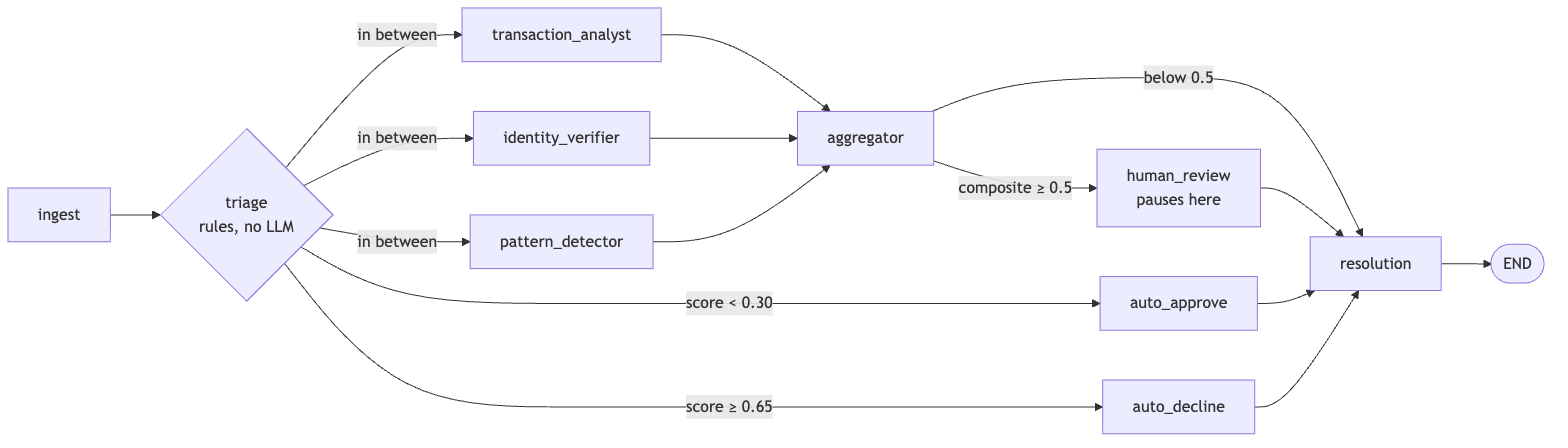

| Part | What it covers | Code |
|---|---|---|
| 1 | Setup | |
| 2 | The wiring | `graph.py: build_graph()` |
| 3 | The fast paths: no LLM | |
| 4 | The investigate path, paused for review | |
| 5 | The human decision | `ui/logic.py: resume_transaction()` |
| 6 | Any transaction ID | |
| 7 | Recap and things to try | |

---
## Part 1 · Setup

### Setup
The next cell connects the notebook to the project. It gives this notebook **its own** database files in `.notebook_state/`, so nothing here touches the Streamlit app's data. It prints which LLM this run uses and whether its key is set (never the key itself). Set `SHOW_LIVE_LOGS = True` to see each node's live log line.

Importing `graph` builds the real compiled graph with a SQLite checkpointer and store, pointed at this notebook's own files.

In [1]:
# ── Settings ────────────────────────────────────────────────────────────
SHOW_LIVE_LOGS = False  # True = print every node's live log line, like the terminal does
LLM_MODEL = ""  # "" = default (gemini-3.5-flash). Busy (503) or out of quota (429)? Try e.g. "gemini-3.8-flash"

# Setup: run from the repo root, and give this notebook its own database files in
# .notebook_state/ so it never touches the app's checkpoints.sqlite / account_memory.sqlite.
import logging
import os
import sys
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    # Google Colab: the notebook needs the whole repo (it imports core/, agents/, tools/),
    # so clone it and install the pinned packages on first run; later runs pull updates.
    import subprocess

    REPO = Path("/content/fintech-agent")
    if not REPO.exists():
        print("Colab: cloning the repo and installing packages (about a minute)...")
        subprocess.run(["git", "clone", "-q", "-b", "develop-gemini",
                        "https://github.com/iam-suraj-kumar/fintech-agent.git", str(REPO)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
        print("Done. If a later cell fails to import, use Runtime > Restart session and run this cell again.")
    else:
        # Already cloned in this Colab session: pick up any fixes pushed since.
        # (Code already imported stays old until Runtime > Restart session.)
        pulled = subprocess.run(["git", "-C", str(REPO), "pull", "-q", "--ff-only"], capture_output=True, text=True)
        if pulled.returncode != 0:
            print("Colab: could not update the repo:", pulled.stderr.strip())
    os.chdir(REPO)
    try:
        from google.colab import userdata  # add GEMINI_API_KEY under the key icon (Secrets) in the sidebar

        os.environ.setdefault("GEMINI_API_KEY", userdata.get("GEMINI_API_KEY"))
    except Exception:
        print("No GEMINI_API_KEY secret found: notebooks 00 and 01 still work; 02-04 need it.")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
STATE_DIR = ROOT / ".notebook_state"
STATE_DIR.mkdir(exist_ok=True)
os.environ["CHECKPOINT_DB_PATH"] = str(STATE_DIR / "03_checkpoints.sqlite")
os.environ["MEMORY_DB_PATH"] = str(STATE_DIR / "03_memory.sqlite")
os.environ.setdefault("FASTMCP_LOG_LEVEL", "WARNING")  # quiet the MCP server subprocess
warnings.filterwarnings("ignore")

from dotenv import load_dotenv

load_dotenv(ROOT / ".env")  # never overrides the two database paths set above
if LLM_MODEL:
    os.environ["LLM_MODEL"] = LLM_MODEL  # the setting above wins over .env

import pandas as pd

pd.set_option("display.max_colwidth", None)  # show agent findings in full, not cut off with "..."


def trace_table(audit_log: list[dict]) -> pd.DataFrame:
    """One readable line per audit entry (entries have different fields, so a raw table is mostly blanks)."""
    def detail(e: dict) -> str:
        if e["kind"] == "tool_call":
            return f"calls {e['tool']}({e['args']})"
        if e["kind"] == "tool_result":
            return f"{e['tool']} returned {e['result']}"
        return str(e.get("text", ""))
    return pd.DataFrame([{"node": e.get("node", ""), "kind": e["kind"], "detail": detail(e)} for e in audit_log])

from html import escape

from langchain_core.runnables.graph import NodeStyles

# Explicit colours so the boxes read on both light and dark themes
# (LangGraph's default fills are pale but leave the text colour to the theme).
GRAPH_STYLES = NodeStyles(
    default="fill:#DCE6FA,stroke:#2459C2,stroke-width:1px,color:#15202E,line-height:1.2",
    first="fill:#2459C2,stroke:#2459C2,color:#FFFFFF",
    last="fill:#2F7A4A,stroke:#2F7A4A,color:#FFFFFF",
)


class _MermaidGraph:
    """Displays Mermaid code as a diagram. JupyterLab and VS Code draw Mermaid themselves;
    Colab doesn't, so there the browser draws it with Mermaid's JavaScript."""

    def __init__(self, source: str):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        html = (
            '<div style="background:#fff;padding:10px;border-radius:6px;display:inline-block">'
            '<pre class="mermaid">' + escape(self.source) + "</pre></div>"
            '<script type="module">'
            'import mermaid from "https://cdn.jsdelivr.net/npm/mermaid@11.4.1/dist/mermaid.esm.min.mjs";'
            'mermaid.initialize({startOnLoad: false, theme: "default"});'
            'await mermaid.run({querySelector: "pre.mermaid:not([data-processed])"});'
            "</script>"
        )
        if "google.colab" in sys.modules:
            return {"text/html": html}
        return {"text/markdown": "```mermaid\n" + self.source + "\n```"}


def show_graph(app):
    """Draw a compiled LangGraph graph."""
    return _MermaidGraph(app.get_graph().draw_mermaid(node_colors=GRAPH_STYLES))

import core.audit  # noqa: F401  (creates the "fraud_guard" live logger)
from core.llm import llm_model, llm_provider

logging.getLogger("fraud_guard").setLevel(logging.INFO if SHOW_LIVE_LOGS else logging.WARNING)
pd.set_option("display.max_colwidth", 160)
key = {"gemini": "GEMINI_API_KEY", "openai": "OPENAI_API_KEY"}.get(llm_provider(), "?")
print(f"LLM: {llm_provider()} / {llm_model()}   ({key} set: {'yes' if os.environ.get(key) else 'NO'})")

import uuid

from core.state import new_state
from data.synthetic_transactions import SCENARIOS, get_scenario
from graph import build_graph, graph


def new_thread(name: str) -> dict:
    # One thread_id per run, like the app: the checkpointer keys saved state by it.
    return {"configurable": {"thread_id": f"{name}-{uuid.uuid4().hex[:6]}"}}


def audit_table(values: dict) -> pd.DataFrame:
    return trace_table(values["audit_log"])

LLM: gemini / gemini-3.5-flash   (GEMINI_API_KEY set: yes)


---
## Part 2 · The wiring

`build_graph()` is the whole pipeline in about 30 lines: add the 10 nodes, connect them with edges, add the two routers as conditional edges, and compile with a checkpointer, a store and `interrupt_before=["human_review"]`. This is the real code:

In [2]:
import inspect

print(inspect.getsource(build_graph))

def build_graph(nodes: NodeMap, checkpointer=None, store=None):
    builder = StateGraph(TransactionState)

    for name in NODE_NAMES:
        builder.add_node(name, nodes[name])

    builder.add_edge(START, "ingest")
    builder.add_edge("ingest", "triage")
    builder.add_conditional_edges(
        "triage",
        route_after_triage,
        {
            "auto_approve": "auto_approve",
            "auto_decline": "auto_decline",
            "transaction_analyst": "transaction_analyst",
            "identity_verifier": "identity_verifier",
            "pattern_detector": "pattern_detector",
        },
    )
    builder.add_edge("auto_approve", "resolution")
    builder.add_edge("auto_decline", "resolution")
    builder.add_edge("transaction_analyst", "aggregator")
    builder.add_edge("identity_verifier", "aggregator")
    builder.add_edge("pattern_detector", "aggregator")
    builder.add_conditional_edges(
        "aggregator",
        route_after_aggregator,
        {"human_revi

LangGraph can draw the compiled graph itself. Dotted arrows are conditional edges; `human_review` is marked as an interrupt.

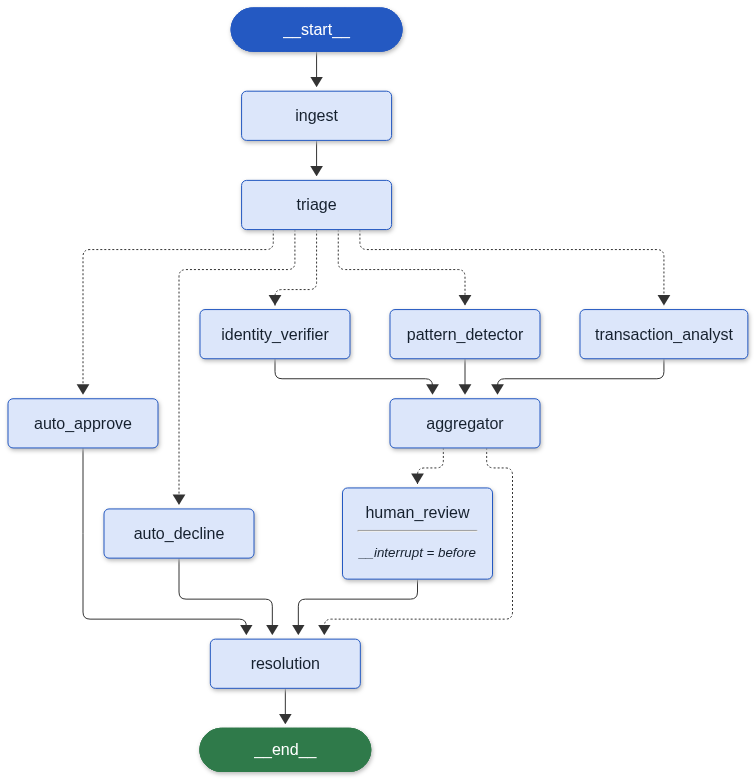

In [3]:
show_graph(graph)

---
## Part 3 · The fast paths: no LLM

Most traffic ends here. A $6.50 coffee is approved and a US-to-Nigeria purchase 10 minutes after a US one is declined, both by triage alone, in milliseconds.

In [4]:
import time

for name in ("clean_coffee", "impossible_travel"):
    start = time.time()
    out = graph.invoke(new_state(SCENARIOS[name]), new_thread(name))
    print(f"{name}: triage {out['triage_score']:.2f} -> {out['triage_decision']} -> {out['final_decision']} ({(time.time() - start) * 1000:.0f} ms)")
    display(audit_table(out))

clean_coffee: triage 0.01 -> auto_approve -> approved (13 ms)


,node,kind,detail
0,ingest,info,received transaction txn_001
1,triage,info,score=0.01 decision=auto_approve
2,auto_approve,info,triage score below investigation threshold
3,resolution,decision,final_decision=approved


impossible_travel: triage 0.92 -> auto_decline -> declined (4 ms)


,node,kind,detail
0,ingest,info,received transaction txn_002
1,triage,info,score=0.92 decision=auto_decline
2,auto_decline,info,triage score indicates high-confidence fraud
3,resolution,decision,final_decision=declined


---
## Part 4 · The investigate path, paused for review

The $18,000 wire scores in the middle band, so triage fans out to the three specialists **in parallel**, the aggregator scores their findings, and if the composite score is 0.5 or more the graph **stops before `human_review`**. `invoke()` returns, and `get_state()` shows where it is waiting.

In [5]:
wire_config = new_thread("borderline_wire")
start = time.time()
graph.invoke(new_state(SCENARIOS["borderline_wire"]), wire_config)
snapshot = graph.get_state(wire_config)

print(f"took {time.time() - start:.1f}s · waiting before: {snapshot.next}")
print(f"triage {snapshot.values['triage_score']:.2f} · composite {snapshot.values['composite_score']:.2f}")
print("aggregator reasoning:", snapshot.values["aggregate_reasoning"])

took 51.7s · waiting before: ('human_review',)
triage 0.64 · composite 0.78
aggregator reasoning: While identity and device checks confirm the transaction originated from a recognized device and location (San Francisco, CA), the transaction exhibits critical fraud indicators. An $18,000 wire transfer significantly exceeds the account's historical spending range ($500-$5,000) and routes to a newly added international beneficiary via a high-risk merchant. This specific behavior strongly matches established historical fraud patterns involving rapid international transfers to new accounts, justifying an elevated risk score.


The audit trail shows every step so far, including each specialist's tool calls. The three specialists' entries interleave because they ran at the same time:

In [6]:
audit_table(snapshot.values)

,node,kind,detail
0,ingest,info,received transaction txn_003
1,triage,info,score=0.64 decision=investigate
2,identity_verifier,tool_call,calls device_fingerprint({'device_id': 'dev_known_1'})
3,identity_verifier,tool_call,calls geolocation({'ip': '136.24.0.1'})
4,identity_verifier,tool_result,"device_fingerprint returned {'known': True, 'first_seen_days_ago': 412}"
5,identity_verifier,tool_result,"geolocation returned {'country': 'US', 'city': 'San Francisco', 'region': 'California', 'isp': 'Webpass Inc.'}"
6,identity_verifier,summary,"The device used for this transaction (`dev_known_1`) is a recognized device associated with the account, first seen 412 days ago. Additionally, the IP addre..."
7,pattern_detector,tool_call,calls account_history({'account_id': 'acct_2002'})
8,pattern_detector,tool_call,calls similar_fraud_cases({'description': 'wire transfer to new beneficiary Global Trading Partners LLC large amount international'})
9,pattern_detector,tool_result,"account_history returned {'typical_range': [500, 5000], 'country': 'US', 'avg_txn_count_per_week': 3}"


---
## Part 5 · The human decision

This is what the Streamlit review queue and `cli.py review` do (`ui/logic.py: resume_transaction()`): write the reviewer's choice into the saved state, then continue the same thread. The choices are `approve`, `decline` or `escalate`.

In [7]:
graph.update_state(wire_config, {"human_decision": "approve"})
final = graph.invoke(None, wire_config)

print("final decision:", final["final_decision"])
audit_table(final).tail(3)

final decision: approved


,node,kind,detail
19,aggregator,summary,"While identity and device checks confirm the transaction originated from a recognized device and location (San Francisco, CA), the transaction exhibits crit..."
20,human_review,info,awaiting reviewer decision (composite_score=0.78)
21,resolution,decision,final_decision=approved


---
## Part 6 · Any transaction ID

Type any ID; it becomes a reproducible synthetic transaction (notebook 01, Part 2). If it pauses for review, this cell declines it.

In [8]:
MY_ID = "conference-demo-7"

config = new_thread(MY_ID)
out = graph.invoke(new_state(get_scenario(MY_ID)), config)
if graph.get_state(config).next:
    graph.update_state(config, {"human_decision": "decline"})
    out = graph.invoke(None, config)
print(f"{MY_ID}: ${out['transaction']['amount']:,.2f} · triage {out['triage_score']:.2f} ({out['triage_decision']}) · final: {out['final_decision']}")

conference-demo-7: $833.12 · triage 0.01 (auto_approve) · final: approved


---
## Part 7 · Recap and things to try

**What happened:** one graph handled every path. Cheap rules settled the obvious cases; the ambiguous wire fanned out to three agents in parallel, was scored, and **paused**; a human's decision resumed the same thread to a final, audited outcome.

**Try this**
- Resume a paused run with `"escalate"` instead and check `final_decision`.
- Run `borderline_restart_demo` and read the analyst's sanctions finding in the audit table.
- Try a few IDs in Part 6 until one pauses for review.

**Next:** `04_persistence_and_memory.ipynb`: kill the process mid-review and pick up where it left off.